# KO2 — Somatic Mutations Show Higher AlphaMissense Pathogenicity Scores in PDAC Driver Genes

## Overview

This notebook tests **Key Objective 2**: that somatic mutations carry higher AlphaMissense (AM) pathogenicity scores than germline mutations in the four canonical PDAC driver genes (KRAS, TP53, SMAD4, CDKN2A), and that 73 additional genes show similarly driver-like pathogenicity metrics. It reports per-gene descriptive statistics and a combined AM score distribution plot for the four driver genes, then loads a pre-computed gene-ranking table (CLES lower bound ≥ 0.7, pathogenic max-PDAC-AM-score) to compare the four drivers against the 73 driver-like genes. The notebook produces two figures — a combined driver-gene distribution plot and a two-panel gene-ranking figure — that are exported for use in the final report.

## Data

**Input**
- `../Data/merged_tcga_1000G.parquet` — merged table of somatic (TCGA-PAAD, `source == 'TCGA'`) and germline (1000 Genomes, `source == '1000G'`) mutations.
  Columns used: `source`, `gene_name`, `sample_id`, `am_pathogenicity`.
- `../Data/driver_like_genes.parquet` — pre-computed gene-ranking table (77 rows: 4 canonical drivers + 73 driver-like genes), generated upstream by `Data_Preparation/gene_selection.ipynb`.
  Columns used: `rank`, `gene_name`, `is_driver`, `cles_lb`, `max_pdac`, `n_pdac`, `n_healthy`, `pdac_indiv`, `healthy_indiv`.

**Processing**
- Split the merged table into `tcga` (somatic) and `g1000` (germline) by `source`.
- Filter to the 4 canonical driver genes (`DRIVER_GENES`) for the descriptive statistics and Figure 1.
- Load the ranking table and lazily fetch raw per-gene AM-score arrays (via `_get_sc`) for the ranking figure.

**Output**
- `../Figures/KO2_driver_gene_distributions.png` / `.pdf` — Figure 1 (combined driver-gene distributions)
- `../Figures/KO2_driver_gene_ranking.png` / `.pdf` — Figure 2 (driver & driver-like gene ranking)

## Method

- **Per-gene descriptive statistics**: n / median / mean AM score (somatic vs germline) for the 4 canonical driver genes.
- **Combined distribution plot**: 2×2 grid of histogram + KDE per gene, shared PDAC/Healthy colour scheme, AM-threshold colour strip.
- **Driver-like gene selection** (computed upstream, reproduced via `driver_like_genes.parquet`): genes with **CLES lower bound (95% CI) ≥ 0.70** on raw PDAC AM scores, **max PDAC AM score ≥ 0.564** (pathogenic), and **≥ 2 PDAC patients** carrying a pathogenic mutation in the gene.
- **Two-panel ranking figure**: left = per-gene AM-score boxplots (PDAC above-centre / Healthy below, median + max lines), right = CLES-lower-bound bars; the 4 canonical drivers are pinned first (bolded), remaining genes ordered by descending CLES_LB.

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup & Data Loading | Imports, plotting style, AM thresholds/colour constants (incl. `DRIVER_GENES`), load `merged_tcga_1000G.parquet`, split into PDAC/Healthy, set up the figure output directory |
| 2 | Descriptive Statistics — Driver Genes | Per-gene n / median / mean AM scores (somatic vs germline) for KRAS, TP53, SMAD4, CDKN2A |
| 3 | Figure 1 — Driver Gene Score Distributions | Combined 2×2 histogram+KDE distribution plot for the 4 driver genes; saved as `KO2_driver_gene_distributions.{png,pdf}` |
| 4 | Driver-like Gene Selection | Load `driver_like_genes.parquet`; report the 73 additional genes meeting the driver-like criteria (CLES_LB ≥ 0.7, max PDAC AM pathogenic, ≥ 2 pathogenic-PDAC patients) |
| 5 | Figure 2 — Driver & Driver-like Gene Ranking | Two-panel figure: AM-score boxplots + CLES_LB bars for all 77 genes (4 drivers pinned, 73 driver-like ranked by descending CLES_LB); saved as `KO2_driver_gene_ranking.{png,pdf}` |

## 1. Setup & Data Loading

In [2]:
import pathlib
import polars as pl
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 130})

In [4]:
COLOR_PDAC      = '#E69F00'   # orange    — TCGA / PDAC  (Wong palette)
COLOR_HEALTHY   = '#56B4E9'   # sky-blue  — 1000G / Healthy
COLOR_BENIGN    = '#2065ab'   # RdBu_r 0.10 — benign
COLOR_UNCERTAIN = '#b1d5e7'   # RdBu_r 0.35 — uncertain
COLOR_PATH      = '#b1182b'   # RdBu_r 0.90 — pathogenic

DRIVER_GENES  = ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']
AM_BENIGN_MAX = 0.34    # AlphaMissense: AM <= 0.34  -> benign
AM_PATH_MIN   = 0.564   # AlphaMissense: AM >= 0.564 -> pathogenic

# DATA_PATH = 'C:/2604_BRP/Data/merged_tcga_1000G.parquet'   # coworker path
DATA_PATH = 'C:/Users/daane/Desktop/DATA/merged_tcga_1000G.parquet'

In [5]:
df = (
    pl.read_parquet(DATA_PATH)
    .select(['source', 'gene_name', 'sample_id', 'am_pathogenicity'])
)
tcga  = df.filter(pl.col('source') == 'TCGA')
g1000 = df.filter(pl.col('source') == '1000G')

print(f'TCGA rows : {len(tcga):,}')
print(f'1000G rows: {len(g1000):,}')

out_dir = pathlib.Path('../Figures')
out_dir.mkdir(exist_ok=True)

TCGA rows : 15,695
1000G rows: 32,063,253


## 2. Descriptive Statistics — Driver Genes

In [6]:
rows = []
for gene in DRIVER_GENES:
    for label, subset in [('PDAC — somatic', tcga), ('Healthy — germline', g1000)]:
        s = subset.filter(pl.col('gene_name') == gene)['am_pathogenicity'].drop_nulls()
        rows.append(dict(
            Gene   = gene,
            Group  = label,
            n      = len(s),
            median = round(float(s.median()), 4) if len(s) > 0 else None,
            mean   = round(float(s.mean()),   4) if len(s) > 0 else None,
        ))

pl.Config.set_tbl_rows(-1)
pl.DataFrame(rows)

Gene,Group,n,median,mean
str,str,i64,f64,f64
"""KRAS""","""PDAC — somatic""",107,0.9977,0.9969
"""KRAS""","""Healthy — germline""",0,null,null
"""TP53""","""PDAC — somatic""",61,0.9928,0.9291
"""TP53""","""Healthy — germline""",2524,0.0724,0.0732
"""SMAD4""","""PDAC — somatic""",15,0.9994,0.9979
"""SMAD4""","""Healthy — germline""",12,0.1593,0.1535
"""CDKN2A""","""PDAC — somatic""",7,0.7859,0.7421
"""CDKN2A""","""Healthy — germline""",156,0.1514,0.1952


## 3. Figure 1 — Driver Gene Score Distributions

In [7]:
def _safe_kde(arr, n_max=50_000):
    # Subsample before KDE; filter NaN/Inf first.
    arr = arr[np.isfinite(arr)]
    if len(arr) == 0:
        return None
    rng = np.random.default_rng(0)
    if len(arr) > n_max:
        arr = rng.choice(arr, n_max, replace=False)
    return gaussian_kde(arr, bw_method='scott')


def _add_am_colorbar(ax, y_bot=-0.30, ht=0.11, x_min=0.0, x_max=1.0):
    # Coloured strip below x-axis showing benign / uncertain / pathogenic zones.
    from matplotlib.patches import Rectangle
    tr = ax.get_xaxis_transform()   # x: data coords, y: axes fraction
    for x0, x1, color, label in [
        (0,              AM_BENIGN_MAX, COLOR_BENIGN,    'Benign'),
        (AM_BENIGN_MAX,  AM_PATH_MIN,   COLOR_UNCERTAIN, 'Uncertain'),
        (AM_PATH_MIN,    1.0,           COLOR_PATH,      'Pathogenic'),
    ]:
        vx0, vx1 = max(x0, x_min), min(x1, x_max)
        if vx0 >= vx1:
            continue
        ax.add_patch(Rectangle(
            (vx0, y_bot), vx1 - vx0, ht,
            transform=tr, color=color, alpha=0.30, clip_on=False, zorder=2,
        ))
        ax.text((vx0 + vx1) / 2, y_bot + ht / 2, label,
                transform=tr, ha='center', va='center',
                fontsize=6.5, color=color, fontweight='bold', clip_on=False)

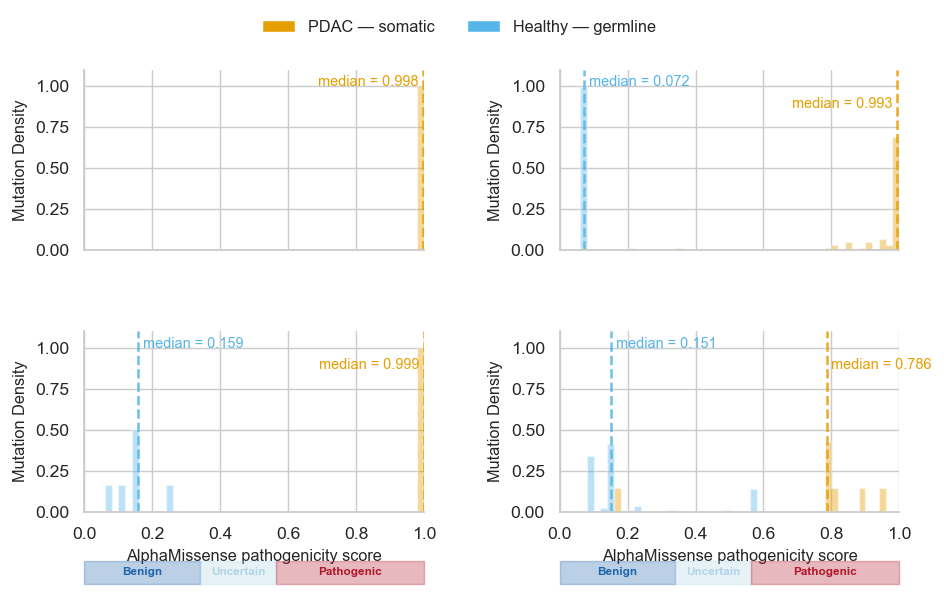

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [8]:
bins = np.linspace(0, 1, 51)

LAYOUT = [
    (0, 0, 'KRAS'),
    (0, 1, 'TP53'),
    (1, 0, 'SMAD4'),
    (1, 1, 'CDKN2A'),
]

fig, axes = plt.subplots(
    2, 2, figsize=(183/25.4, 5.0),
    sharex=True, sharey=True,
)
fig.subplots_adjust(
    left=0.10, right=0.97, top=0.90, bottom=0.22,
    hspace=0.45, wspace=0.40,
)

fig.legend(
    handles=[
        Patch(facecolor=COLOR_PDAC,    label='PDAC — somatic'),
        Patch(facecolor=COLOR_HEALTHY, label='Healthy — germline'),
    ],
    loc='upper center', bbox_to_anchor=(0.5, 1.00),
    ncol=2, frameon=False, fontsize=9,
)

for row, col, gene in LAYOUT:
    ax = axes[row][col]

    pdac_arr = tcga.filter(pl.col('gene_name') == gene)['am_pathogenicity'].drop_nulls().to_numpy()
    hlth_arr = g1000.filter(pl.col('gene_name') == gene)['am_pathogenicity'].drop_nulls().to_numpy()

    groups = [
        (hlth_arr, COLOR_HEALTHY),
        (pdac_arr, COLOR_PDAC),
    ]
    medians = []
    for arr, color in groups:
        if len(arr) == 0:
            continue
        w = np.ones(len(arr)) / len(arr)
        ax.hist(arr, bins=bins, weights=w, color=color, alpha=0.40, histtype='stepfilled')
        medians.append((float(np.median(arr)), color))

    ax.set_ylim(0, 1.10)
    for i, (med, color) in enumerate(medians):
        ax.axvline(med, color=color, lw=1.4, ls='--', alpha=0.85)
        if med > 0.87:
            ax.text(med - 0.013, 1.00 - i * 0.13,
                    f'median = {med:.3f}', color=color, fontsize=8, ha='right')
        else:
            ax.text(med + 0.013, 1.00 - i * 0.13,
                    f'median = {med:.3f}', color=color, fontsize=8, ha='left')

    ax.set_xlim(0, 1)
    ax.set_ylabel('Mutation Density', fontsize=9)
    if col == 1:
        ax.tick_params(axis='y', labelleft=True)
    if row == 1:
        ax.set_xlabel('AlphaMissense pathogenicity score', fontsize=9)
    sns.despine(ax=ax)

_add_am_colorbar(axes[1][0], y_bot=-0.40, ht=0.13)
_add_am_colorbar(axes[1][1], y_bot=-0.40, ht=0.13)

fig.savefig(out_dir / 'KO2_driver_gene_distributions.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO2_driver_gene_distributions.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO2_driver_gene_distributions.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())

## 4. Driver-like Gene Selection

Genes are ranked by the conservative Common Language Effect Size lower bound (**CLES_LB**), computed on raw PDAC AM scores (no per-patient aggregation, no 1000G padding).

**Selection criteria:** CLES_LB ≥ 0.70, max PDAC AM score ≥ 0.564 (pathogenic), and ≥ 2 PDAC patients with a pathogenic mutation (AM ≥ 0.564). The 4 canonical driver genes (KRAS, TP53, SMAD4, CDKN2A) are pinned first; remaining genes are sorted by descending CLES_LB.

In [9]:
# Gene ranking — pre-computed in Data_Preparation/gene_selection.ipynb
_data_dir = pathlib.Path(DATA_PATH).parent
ranking_table     = pl.read_parquet(_data_dir / 'driver_like_genes.parquet')
selected_genes    = set(ranking_table['gene_name'].to_list())
gene_list_ordered = ranking_table['gene_name'].to_list()
driver_genes      = ranking_table.filter(pl.col('is_driver'))['gene_name'].to_list()
driver_like_genes = ranking_table.filter(~pl.col('is_driver'))['gene_name'].to_list()
# pdac_sc / healthy_sc start empty; _get_sc() in the next cell fills them lazily.
pdac_sc, healthy_sc = {}, {}

print(f'Genes in ranking table : {len(selected_genes)}')
print(f'  - canonical drivers  : {len(driver_genes)}  {driver_genes}')
print(f'  - driver-like genes  : {len(driver_like_genes)}')

pl.Config.set_tbl_rows(-1)
ranking_table

Genes in ranking table : 77
  - canonical drivers  : 4  ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']
  - driver-like genes  : 73


rank,gene_name,is_driver,cles_lb,max_pdac,n_pdac,n_healthy,pdac_indiv,pdac_path_indiv,healthy_indiv,healthy_path_indiv
u32,str,bool,f64,f64,i64,i64,i64,i64,i64,i64
1,"""KRAS""",true,0.9453,0.9984,107,0,106,106,0,0
2,"""TP53""",true,0.9108,0.9996,61,2524,61,58,2494,2
3,"""SMAD4""",true,0.8539,1.0,15,12,15,15,12,0
4,"""CDKN2A""",true,0.755,0.9567,7,156,7,6,155,0
5,"""KDM2B""",false,0.747,0.9999,5,71,2,2,71,0
6,"""TAOK2""",false,0.7,0.9999,4,556,2,2,545,8
7,"""MAGI2""",false,0.7519,0.9998,7,71,3,2,67,0
8,"""MEX3C""",false,0.7068,0.9996,4,219,2,2,214,3
9,"""LRP1B""",false,0.7182,0.9996,15,2848,5,3,2026,24


## 5. Figure 2 — Driver & Driver-like Gene Ranking

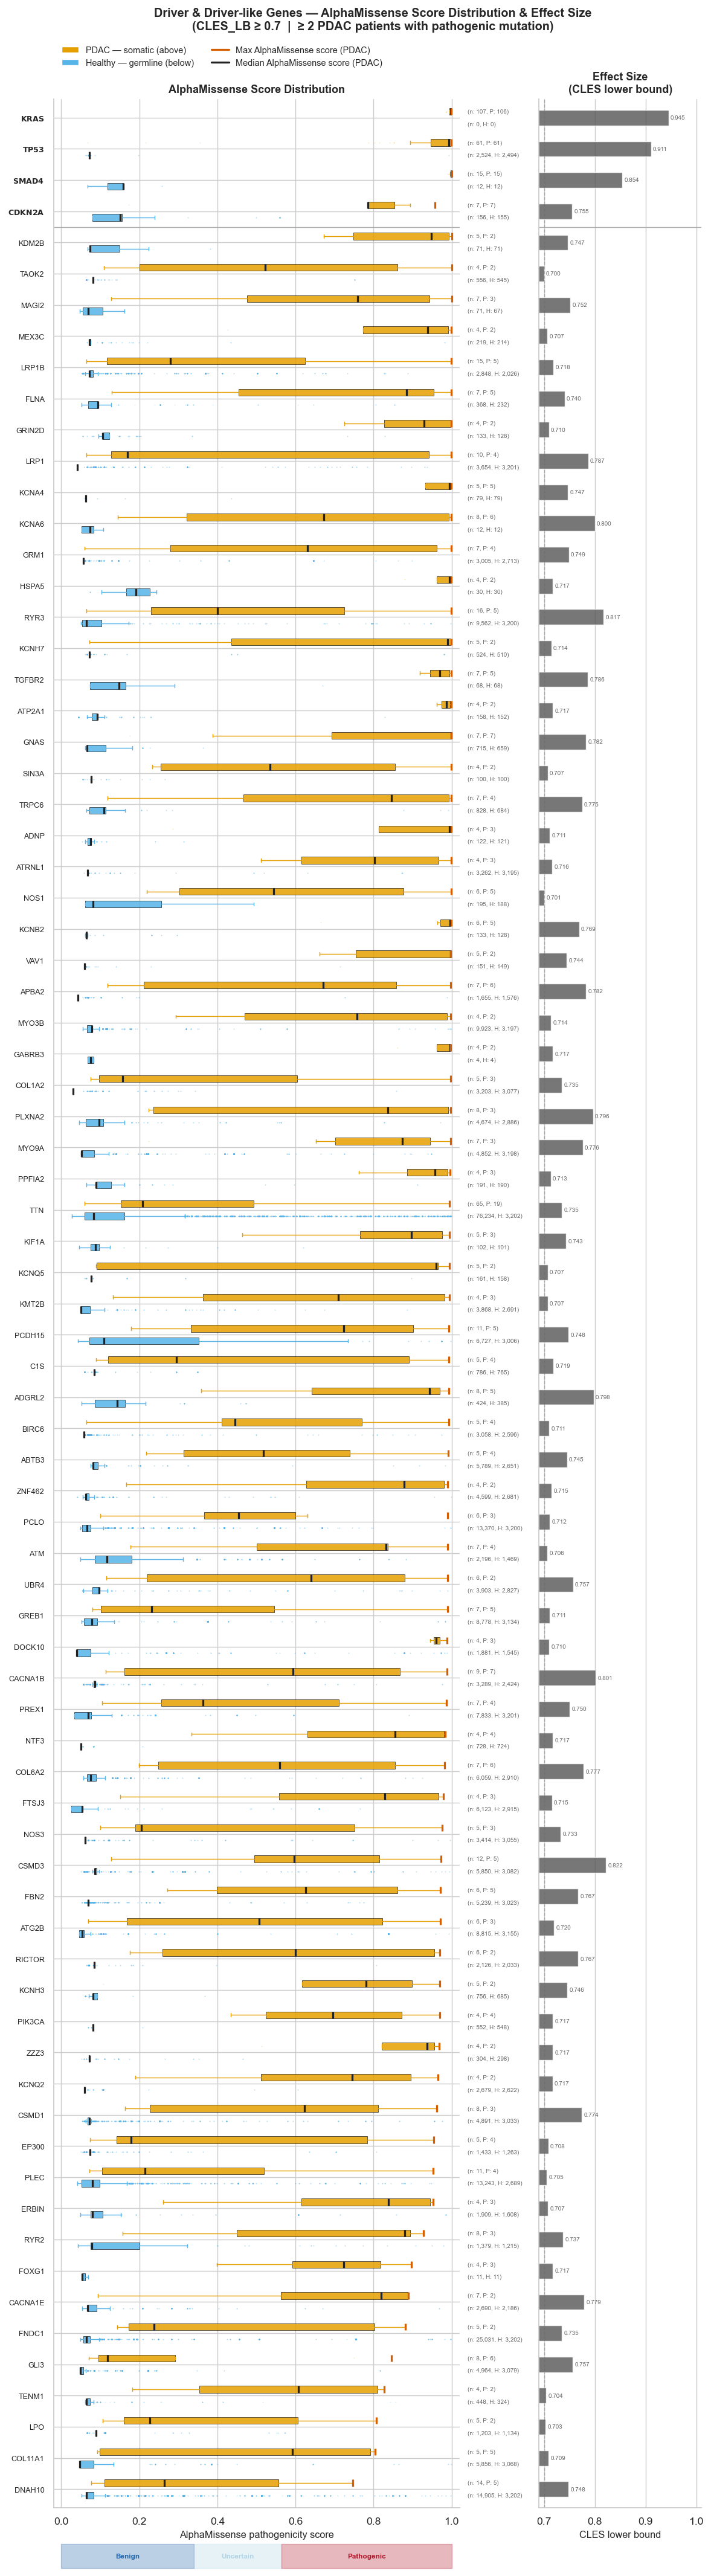

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [10]:
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

# ── Derive display data from ranking_table ────────────────────────────────────
_rows        = ranking_table.to_dicts()[::-1]   # reversed: rank-1 at top
_n           = len(_rows)
_genes       = [r['gene_name']     for r in _rows]
_cles        = [r['cles_lb']       for r in _rows]
_n_pdacs     = [r['n_pdac']        for r in _rows]
_n_hltys     = [r['n_healthy']     for r in _rows]
_pdac_indivs = [r['pdac_indiv']    for r in _rows]
_hlth_indivs = [r['healthy_indiv'] for r in _rows]
_y           = list(range(_n))
_DSET        = set(DRIVER_GENES)
_nd          = sum(1 for g in _genes if g in _DSET)
SEP          = _n - _nd - 0.5

def _get_sc(df, gene_list, existing):
    missing = [g for g in gene_list if g not in existing]
    out = dict(existing)
    if missing:
        out.update({
            row['gene_name']: np.array(row['scores'])
            for row in (
                df
                .filter(pl.col('gene_name').is_in(missing))
                .filter(pl.col('am_pathogenicity').is_not_null())
                .group_by('gene_name')
                .agg(pl.col('am_pathogenicity').alias('scores'))
            ).iter_rows(named=True)
        })
    return out

_fp = _get_sc(tcga,  _genes, pdac_sc)
_fh = _get_sc(g1000, _genes, healthy_sc)
_pd = [_fp.get(g, np.array([])) for g in _genes]
_hd = [_fh.get(g, np.array([])) for g in _genes]

# ── Figure ────────────────────────────────────────────────────────────────────
COLOR_CLES = '#555555'
OFFSET, BOX_W = 0.20, 0.22

fig = plt.figure(figsize=(11, _n * 0.42 + 1.0))
gs  = gridspec.GridSpec(
    1, 2, figure=fig,
    width_ratios=[4.5, 1.8],
    wspace=0.28, left=0.13, right=0.88, top=0.96, bottom=0.04,
)
ax_box  = fig.add_subplot(gs[0])
ax_cles = fig.add_subplot(gs[1])
YLIM = (-0.6, _n - 0.4)
kw   = dict(vert=False, widths=BOX_W, patch_artist=True, manage_ticks=False)

# ── Left panel: boxplots + median (black) + max (red, PDAC only) ──────────────
for y, p, h, np_, nh, pi_, hi_ in zip(_y, _pd, _hd, _n_pdacs, _n_hltys, _pdac_indivs, _hlth_indivs):
    if len(p) >= 2:
        ax_box.boxplot(
            [p], positions=[y + OFFSET], **kw,
            medianprops  = dict(color='#222222', lw=1.8),
            boxprops     = dict(facecolor=COLOR_PDAC, alpha=0.85, lw=0.4),
            whiskerprops = dict(lw=0.8, color=COLOR_PDAC),
            capprops     = dict(lw=0.8, color=COLOR_PDAC),
            flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                markerfacecolor=COLOR_PDAC, markeredgecolor='none'),
        )
        ax_box.vlines(p.max(),
                      y + OFFSET - BOX_W / 2, y + OFFSET + BOX_W / 2,
                      color='#D55E00', lw=1.8, zorder=4)

    ax_box.text(1.02, y + OFFSET, f'(n: {np_:,}, P: {pi_:,})', va='center',
                transform=ax_box.get_yaxis_transform(), fontsize=5.5, color='#666')

    if len(h) >= 2:
        ax_box.boxplot(
            [h], positions=[y - OFFSET], **kw,
            medianprops  = dict(color='#222222', lw=1.8),
            boxprops     = dict(facecolor=COLOR_HEALTHY, alpha=0.85, lw=0.4),
            whiskerprops = dict(lw=0.8, color=COLOR_HEALTHY),
            capprops     = dict(lw=0.8, color=COLOR_HEALTHY),
            flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                markerfacecolor=COLOR_HEALTHY, markeredgecolor='none'),
        )
    ax_box.text(1.02, y - OFFSET,
                f'(n: {nh:,}, H: {hi_:,})' if hi_ > 0 else '(n: 0, H: 0)',
                va='center', transform=ax_box.get_yaxis_transform(),
                fontsize=5.5, color='#666')

ax_box.set_xlim(-0.02, 1.02)
ax_box.set_ylim(*YLIM)
ax_box.set_yticks(_y)
ax_box.set_yticklabels(
    [f'$\\mathbf{{{g}}}$' if g in _DSET else g for g in _genes], fontsize=7)
ax_box.axhline(SEP, color='#aaa', lw=0.8)
ax_box.set_xlabel('AlphaMissense pathogenicity score', fontsize=9)
ax_box.set_title('AlphaMissense Score Distribution', fontsize=10, pad=6, fontweight='bold')
_add_am_colorbar(ax_box, y_bot=-0.025, ht=0.010)
sns.despine(ax=ax_box)

# ── Right panel: CLES_LB bars ─────────────────────────────────────────────────
cles_min = max(0.69, min(c for c in _cles if c is not None) - 0.01)
ax_cles.barh(_y, _cles, left=0, color=COLOR_CLES, height=0.50, alpha=0.80)
ax_cles.axvline(0.70, color='grey', lw=0.8, ls='--', alpha=0.5)
for y, c in zip(_y, _cles):
    ax_cles.text(c + 0.004, y, f'{c:.3f}', va='center', fontsize=5.5, color='#666')
ax_cles.set_xlim(cles_min, 1.01)
ax_cles.set_ylim(*YLIM)
ax_cles.set_yticks([])
ax_cles.axhline(SEP, color='#aaa', lw=0.8)
ax_cles.set_xlabel('CLES lower bound', fontsize=9)
ax_cles.set_title('Effect Size\n(CLES lower bound)', fontsize=10, pad=6, fontweight='bold')
sns.despine(ax=ax_cles)

# ── Figure title ──────────────────────────────────────────────────────────────
fig.suptitle(
    'Driver & Driver-like Genes — AlphaMissense Score Distribution & Effect Size\n'
    '(CLES_LB ≥ 0.7  |  ≥ 2 PDAC patients with pathogenic mutation)',
    fontsize=11, fontweight='semibold', y=0.995,
)

# ── Legend ────────────────────────────────────────────────────────────────────
leg_handles = [
    Patch(facecolor=COLOR_PDAC,    label='PDAC — somatic (above)'),
    Patch(facecolor=COLOR_HEALTHY, label='Healthy — germline (below)'),
    Line2D([], [], color='#D55E00', lw=1.8, label='Max AlphaMissense score (PDAC)'),
    Line2D([], [], color='#222222', lw=1.8, label='Median AlphaMissense score (PDAC)'),
]
ax_box.legend(
    handles=leg_handles,
    loc='lower left', bbox_to_anchor=(0.0, 1.01),
    bbox_transform=ax_box.transAxes,
    frameon=False, fontsize=8, ncol=2,
)

fig.savefig(out_dir / 'KO2_driver_gene_ranking.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO2_driver_gene_ranking.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO2_driver_gene_ranking.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())